# Experiment 1: Time and frequency domain, and the pendulum

CSAI4014 AISR lab. Builds a signal of known composition, reads its amplitude
spectrum, demonstrates aliasing, then integrates the damped pendulum and measures
how its period depends on amplitude. Figures are written to `figs/`, measured
values to `obs.json`.

In [1]:
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import solve_ivp

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': 0.3})
print('numpy', np.__version__, '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)
obs = {}

numpy 2.5.5 | scipy 1.18.1 | matplotlib 3.11.2


## Part A: a signal of known composition and its spectrum

In [2]:
fs, T = 500.0, 2.0                 # sampling rate (Hz), record length (s)
t = np.arange(0, T, 1/fs)
N = t.size
components = [(5, 1.00), (20, 0.50), (50, 0.25)]   # (frequency Hz, amplitude)

rng = np.random.default_rng(0)     # seeded so the run is reproducible
x = sum(a*np.sin(2*np.pi*f*t) for f, a in components) + 0.20*rng.standard_normal(N)

def amplitude_spectrum(x, fs):
    """One-sided amplitude spectrum scaled to the units of x."""
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(x.size, d=1/fs)
    amp = np.abs(X) * 2.0 / x.size
    amp[0] /= 2.0                  # the DC term is not doubled
    return f, amp

f, amp = amplitude_spectrum(x, fs)
df = fs / N
print(f'N = {N}, T = {T} s, df = {df} Hz, Nyquist = {fs/2} Hz')

measured = []
for f_set, a_set in components:
    band = (f > f_set - 2) & (f < f_set + 2)      # look for the peak near each set frequency
    k = np.argmax(np.where(band, amp, 0))
    measured.append((f_set, float(f[k]), a_set, float(amp[k])))
    print(f'set {f_set:>3} Hz, amp {a_set:.2f}  ->  measured {f[k]:5.1f} Hz, amp {amp[k]:.3f}')

obs['sampling'] = dict(fs=fs, T=T, N=N, df=df, nyquist=fs/2)
obs['spectrum'] = measured

N = 1000, T = 2.0 s, df = 0.5 Hz, Nyquist = 250.0 Hz
set   5 Hz, amp 1.00  ->  measured   5.0 Hz, amp 1.008
set  20 Hz, amp 0.50  ->  measured  20.0 Hz, amp 0.492
set  50 Hz, amp 0.25  ->  measured  50.0 Hz, amp 0.252


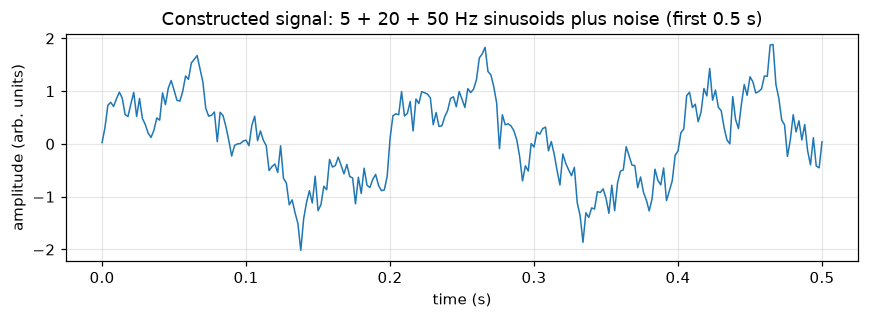

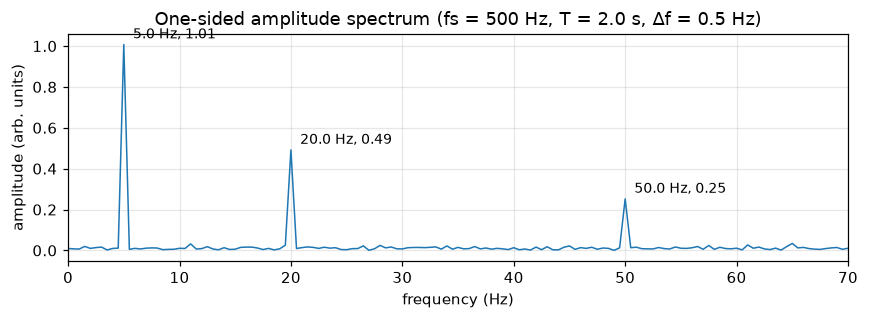

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
m = t <= 0.5
ax.plot(t[m], x[m], lw=1.0, color='tab:blue')
ax.set_xlabel('time (s)'); ax.set_ylabel('amplitude (arb. units)')
ax.set_title('Constructed signal: 5 + 20 + 50 Hz sinusoids plus noise (first 0.5 s)')
fig.tight_layout(); fig.savefig('figs/fig1_1_time_signal.png')

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f, amp, lw=1.0, color='tab:blue')
for f_set, f_m, a_set, a_m in measured:
    ax.annotate(f'{f_m:.1f} Hz, {a_m:.2f}', (f_m, a_m), xytext=(6, 4),
                textcoords='offset points', fontsize=9)
ax.set_xlim(0, 70)
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('amplitude (arb. units)')
ax.set_title(f'One-sided amplitude spectrum (fs = {fs:.0f} Hz, T = {T} s, Δf = {df} Hz)')
fig.tight_layout(); fig.savefig('figs/fig1_2_spectrum.png')

## Spectral leakage: the same signal recorded for T = 1.7 s
With T = 1.7 s, Δf = 1/1.7 ≈ 0.588 Hz, so 5, 20 and 50 Hz no longer fall exactly on bins.

T=1.7 s: set 5 Hz -> peak bin 4.706 Hz, height 0.664 (set 1.0)
T=1.7 s: set 20 Hz -> peak bin 20.000 Hz, height 0.486 (set 0.5)
T=1.7 s: set 50 Hz -> peak bin 50.000 Hz, height 0.259 (set 0.25)


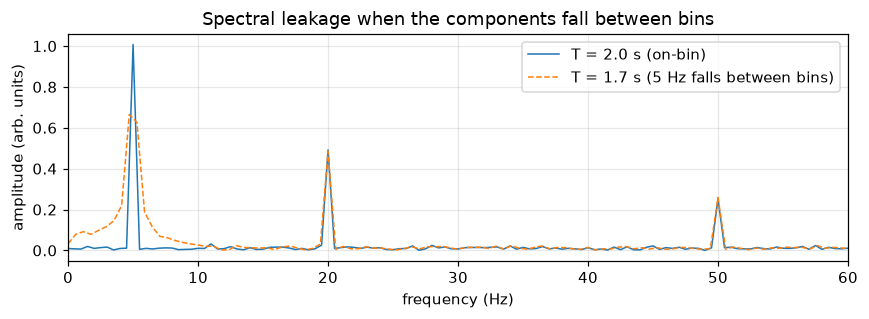

In [4]:
T2 = 1.7
t2 = np.arange(0, T2, 1/fs)
x2 = sum(a*np.sin(2*np.pi*fr*t2) for fr, a in components) + 0.20*np.random.default_rng(0).standard_normal(t2.size)
f2, amp2 = amplitude_spectrum(x2, fs)
leak = []
for f_set, a_set in components:
    band = (f2 > f_set - 2) & (f2 < f_set + 2)
    k = np.argmax(np.where(band, amp2, 0))
    leak.append((f_set, float(f2[k]), a_set, float(amp2[k])))
    print(f'T=1.7 s: set {f_set} Hz -> peak bin {f2[k]:.3f} Hz, height {amp2[k]:.3f} (set {a_set})')
obs['leakage'] = dict(T=T2, df=fs/t2.size, peaks=leak)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(f, amp, lw=1.0, label='T = 2.0 s (on-bin)')
ax.plot(f2, amp2, lw=1.0, ls='--', label='T = 1.7 s (5 Hz falls between bins)')
ax.set_xlim(0, 60); ax.legend()
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('amplitude (arb. units)')
ax.set_title('Spectral leakage when the components fall between bins')
fig.tight_layout(); fig.savefig('figs/fig1_6_leakage.png')

## Part B: aliasing — a 5 Hz sine sampled at 8 Hz

Nyquist = 4.0 Hz; peak appears at 3.0 Hz (expected |8 - 5| = 3 Hz)


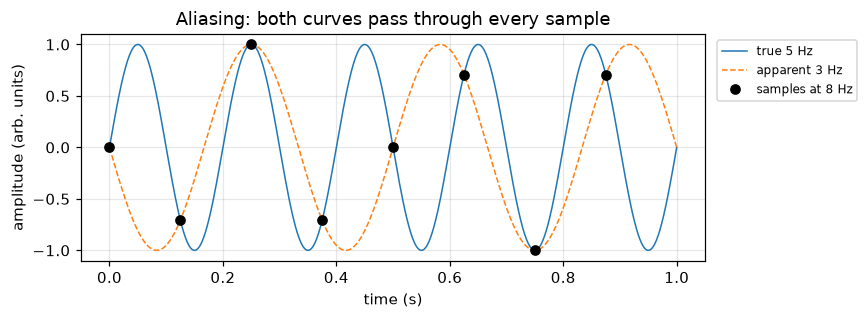

In [5]:
fs_a = 8.0
t_a = np.arange(0, 1.0, 1/fs_a)
x_a = np.sin(2*np.pi*5*t_a)
X_a = np.abs(np.fft.rfft(x_a))
f_a = np.fft.rfftfreq(t_a.size, d=1/fs_a)
alias = float(f_a[np.argmax(X_a)])
print(f'Nyquist = {fs_a/2} Hz; peak appears at {alias} Hz (expected |8 - 5| = 3 Hz)')
obs['alias_peak_hz'] = alias

tf = np.linspace(0, 1, 1000)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tf, np.sin(2*np.pi*5*tf), lw=1.0, label='true 5 Hz')
# sin(2π·5·n/8) = -sin(2π·3·n/8): the apparent signal is a sign-inverted 3 Hz sine
ax.plot(tf, -np.sin(2*np.pi*3*tf), lw=1.0, ls='--', label='apparent 3 Hz')
ax.plot(t_a, x_a, 'ko', ms=6, label='samples at 8 Hz')
ax.set_xlabel('time (s)'); ax.set_ylabel('amplitude (arb. units)')
ax.set_title('Aliasing: both curves pass through every sample')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
fig.tight_layout(); fig.savefig('figs/fig1_3_aliasing.png')

## Part C: the pendulum
θ'' + b θ' + (g/L) sin θ = 0, written as the first-order system (θ, ω).
Here b is the damping coefficient per unit mass (b/m), in s⁻¹.

small-angle period T0 = 2.0061 s


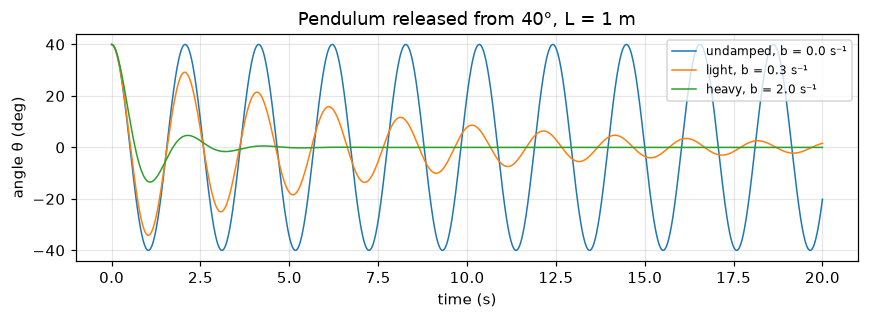

In [6]:
g, L = 9.81, 1.0
T0 = 2*np.pi*np.sqrt(L/g)
print(f'small-angle period T0 = {T0:.4f} s')

def pendulum(t, y, b):
    theta, omega = y                       # solve_ivp calls f(t, y)
    return [omega, -b*omega - (g/L)*np.sin(theta)]

def simulate(theta0_deg, b, T=20.0, n=4000):
    te = np.linspace(0, T, n)
    sol = solve_ivp(pendulum, [0, T], [np.deg2rad(theta0_deg), 0.0], args=(b,),
                    t_eval=te, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0], sol.y[1]

dampings = [(0.0, 'undamped'), (0.3, 'light'), (2.0, 'heavy')]
fig, ax = plt.subplots(figsize=(8, 3))
runs = {}
for b, name in dampings:
    tt, th, om = simulate(40, b)
    runs[b] = (th, om)
    ax.plot(tt, np.rad2deg(th), lw=1.0, label=f'{name}, b = {b} s⁻¹')
ax.set_xlabel('time (s)'); ax.set_ylabel('angle θ (deg)')
ax.set_title('Pendulum released from 40°, L = 1 m')
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figs/fig1_4_pendulum_damping.png')
obs['dampings'] = [b for b, _ in dampings]
obs['T0'] = T0

   5 deg: zero crossings 2.007 s, spectrum 2.000 s, ratio 1.00
  45 deg: zero crossings 2.086 s, spectrum 2.069 s, ratio 1.04
  95 deg: zero crossings 2.417 s, spectrum 2.400 s, ratio 1.21
 135 deg: zero crossings 3.065 s, spectrum 3.000 s, ratio 1.53


 175 deg: zero crossings 5.773 s, spectrum 6.001 s, ratio 2.88


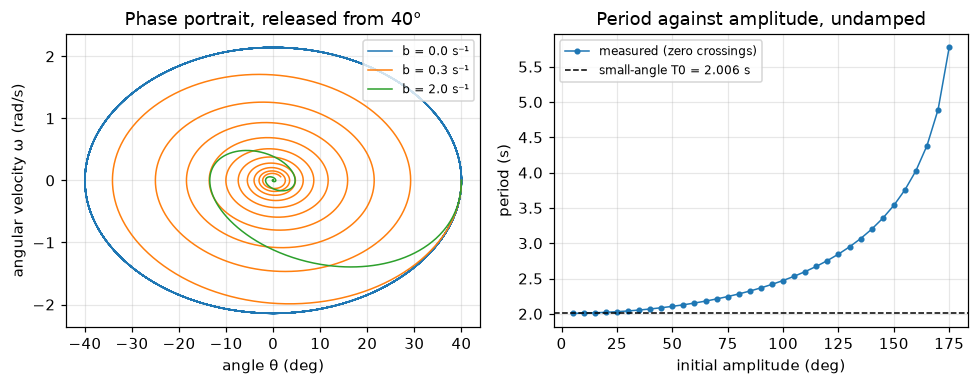

In [7]:
def period_zero_crossings(t, th):
    """Mean interval between upward zero crossings, linearly interpolated."""
    i = np.where((th[:-1] < 0) & (th[1:] >= 0))[0]
    tc = t[i] - th[i]*(t[i+1]-t[i])/(th[i+1]-th[i])
    return float(np.mean(np.diff(tc)))

def period_spectrum(t, th):
    fs2 = 1/(t[1]-t[0])
    A = np.abs(np.fft.rfft(th))
    fr = np.fft.rfftfreq(th.size, 1/fs2)
    pk = fr[1:][np.argmax(A[1:])]          # skip bin 0, which holds the mean
    return float(1/pk)

amps = [5, 45, 95, 135, 175]
rows = []
for a in amps:
    tt, th, _ = simulate(a, 0.0, T=60.0, n=12000)
    tz, ts = period_zero_crossings(tt, th), period_spectrum(tt, th)
    rows.append((a, tz, ts, tz/T0))
    print(f'{a:>4} deg: zero crossings {tz:.3f} s, spectrum {ts:.3f} s, ratio {tz/T0:.2f}')
obs['period_table'] = rows

sweep = np.arange(5, 176, 5)
sweep_T = [period_zero_crossings(*simulate(a, 0.0, T=60.0, n=12000)[:2]) for a in sweep]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6))
for b, name in dampings:
    th, om = runs[b]
    a1.plot(np.rad2deg(th), om, lw=1.0, label=f'b = {b} s⁻¹')
a1.set_xlabel('angle θ (deg)'); a1.set_ylabel('angular velocity ω (rad/s)')
a1.set_title('Phase portrait, released from 40°'); a1.legend(fontsize=8)
a2.plot(sweep, sweep_T, 'o-', ms=3, lw=1.0, label='measured (zero crossings)')
a2.axhline(T0, color='k', ls='--', lw=1.0, label=f'small-angle T0 = {T0:.3f} s')
a2.set_xlabel('initial amplitude (deg)'); a2.set_ylabel('period (s)')
a2.set_title('Period against amplitude, undamped'); a2.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figs/fig1_5_phase_and_period.png')

In [8]:
with open('obs.json', 'w') as fh:
    json.dump(obs, fh, indent=2)
print(json.dumps(obs, indent=1))

{
 "sampling": {
  "fs": 500.0,
  "T": 2.0,
  "N": 1000,
  "df": 0.5,
  "nyquist": 250.0
 },
 "spectrum": [
  [
   5,
   5.0,
   1.0,
   1.007761407576205
  ],
  [
   20,
   20.0,
   0.5,
   0.49171102020634483
  ],
  [
   50,
   50.0,
   0.25,
   0.25208452812036897
  ]
 ],
 "leakage": {
  "T": 1.7,
  "df": 0.5882352941176471,
  "peaks": [
   [
    5,
    4.705882352941177,
    1.0,
    0.6643151202949674
   ],
   [
    20,
    20.0,
    0.5,
    0.4859405439359951
   ],
   [
    50,
    50.0,
    0.25,
    0.25869982226263377
   ]
  ]
 },
 "alias_peak_hz": 3.0,
 "dampings": [
  0.0,
  0.3,
  2.0
 ],
 "T0": 2.0060666807106475,
 "period_table": [
  [
   5,
   2.00702191356248,
   2.000166680556713,
   1.0004761720340691
  ],
  [
   45,
   2.08625587045496,
   2.0691379454034964,
   1.0399733421203654
  ],
  [
   95,
   2.4173843805171558,
   2.4002000166680557,
   1.2050369031904757
  ],
  [
   135,
   3.0651647129328574,
   3.0002500208350695,
   1.5279475714371693
  ],
  [
   175,
  